# Nobel Prize Analysis

Day 79 of Udemy's *100 Days of Code: The Complete Python Pro Bootcamp* (lectures 583 to 590).

On November 27, 1895, Alfred Nobel signed his last will in Paris. His estate was to endow "prizes to those who, during the preceding year, have conferred the greatest benefit to humankind". This notebook analyses the past winners with Pandas, Plotly, Matplotlib and Seaborn. The analysis functions live in the tested package `nobel_analysis`; each section below follows one lecture step.

## Step 1: The goals of the day (lecture 583)

We will create a choropleth map, plotly bar and sunburst charts, Seaborn `.lmplot()` charts with `row`, `hue` and `lowess`, and a Seaborn histogram. The data file `nobel_prize_data.csv` is in `data/` (Google Colab is not needed).

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from nobel_analysis.application import analysis, cleaning
from nobel_analysis.infrastructure.data import load_nobel
from nobel_analysis.presentation import charts

pd.options.display.float_format = '{:,.2f}'.format
df_raw = load_nobel()
df_raw.head()

,year,category,prize,motivation,prize_share,laureate_type,full_name,birth_date,birth_city,birth_country,birth_country_current,sex,organization_name,organization_city,organization_country,ISO
0,1901,Chemistry,The Nobel Prize in Chemistry 1901,"""in recognition of the extraordinary services ...",1/1,Individual,Jacobus Henricus van 't Hoff,1852-08-30,Rotterdam,Netherlands,Netherlands,Male,Berlin University,Berlin,Germany,NLD
1,1901,Literature,The Nobel Prize in Literature 1901,"""in special recognition of his poetic composit...",1/1,Individual,Sully Prudhomme,1839-03-16,Paris,France,France,Male,NaN,NaN,NaN,FRA
2,1901,Medicine,The Nobel Prize in Physiology or Medicine 1901,"""for his work on serum therapy, especially its...",1/1,Individual,Emil Adolf von Behring,1854-03-15,Hansdorf (Lawice),Prussia (Poland),Poland,Male,Marburg University,Marburg,Germany,POL
3,1901,Peace,The Nobel Peace Prize 1901,NaN,1/2,Individual,Frédéric Passy,1822-05-20,Paris,France,France,Male,NaN,NaN,NaN,FRA
4,1901,Peace,The Nobel Peace Prize 1901,NaN,1/2,Individual,Jean Henry Dunant,1828-05-08,Geneva,Switzerland,Switzerland,Male,NaN,NaN,NaN,CHE


## Step 2: Explore and clean the data set (lecture 584)

**Challenge 1:** What is the shape of `df_data`? Which column names? In which year was the prize first awarded, and what is the latest year?

In [2]:
print("shape:", cleaning.data_shape(df_raw))
print("columns:", list(df_raw.columns))
print("first year:", cleaning.first_year(df_raw), "| last year:", cleaning.last_year(df_raw))

shape: (962, 16)
columns: ['year', 'category', 'prize', 'motivation', 'prize_share', 'laureate_type', 'full_name', 'birth_date', 'birth_city', 'birth_country', 'birth_country_current', 'sex', 'organization_name', 'organization_city', 'organization_country', 'ISO']
first year: 1901 | last year: 2020


**Answer:** 962 rows and 16 columns; the first prizes were awarded in 1901 and the data goes up to 2020.

**Challenge 2:** Are there duplicates or NaN values, which columns have them, and why?

In [3]:
print("duplicates:", cleaning.count_duplicates(df_raw))
cleaning.nan_per_column(df_raw)

duplicates: 0


organization_name        255
organization_city        255
organization_country     254
motivation                88
birth_city                31
birth_date                28
sex                       28
birth_country_current     28
birth_country             28
ISO                       28
dtype: int64

**Answer:** no duplicates. Organisation columns are NaN for laureates without a research organisation (many Literature and Peace prizes); birth columns are NaN for organisations that received a prize; `motivation` is missing for some prizes.

**Challenge 3:** Convert `birth_date` to datetimes and add `share_pct`.

In [4]:
df_data = cleaning.clean(df_raw)
df_data[["birth_date", "prize_share", "share_pct"]].head()

,birth_date,prize_share,share_pct
0,1852-08-30,1/1,100.00
1,1839-03-16,1/1,100.00
2,1854-03-15,1/1,100.00
3,1822-05-20,1/2,50.00
4,1828-05-08,1/2,50.00


## Step 3: Bar and donut charts (lecture 585)

**Challenge 1:** Come up with 3 questions of your own about this data. For example: what percentage of the laureates were women? How many prizes were given in each category?

**Challenge 2:** What percentage of all prizes went to women? Show it as a donut chart.

In [5]:
print(f"women: {analysis.women_percentage(df_data):.2f} %")
charts.sex_donut_chart(df_data).show()

women: 6.21 %


**Challenge 3:** Who were the first three women to win, what for, and in which country were they born? Which laureates won more than once?

In [6]:
display(analysis.first_female_laureates(df_data)[["year", "category", "full_name", "birth_country"]])
analysis.repeat_winners(df_data)[["full_name", "year", "category"]]

,year,category,full_name,birth_country
18,1903,Physics,"Marie Curie, née Sklodowska",Russian Empire (Poland)
29,1905,Peace,"Baroness Bertha Sophie Felicita von Suttner, n...",Austrian Empire (Czech Republic)
51,1909,Literature,Selma Ottilia Lovisa Lagerlöf,Sweden


,full_name,year,category
89,Comité international de la Croix Rouge (Intern...,1917,Peace
215,Comité international de la Croix Rouge (Intern...,1944,Peace
348,Comité international de la Croix Rouge (Intern...,1963,Peace
306,Frederick Sanger,1958,Chemistry
505,Frederick Sanger,1980,Chemistry
297,John Bardeen,1956,Physics
424,John Bardeen,1972,Physics
278,Linus Carl Pauling,1954,Chemistry
340,Linus Carl Pauling,1962,Peace
18,"Marie Curie, née Sklodowska",1903,Physics


**Challenge 4:** In how many categories are prizes awarded, and which has the most? When was the first Economics prize and who won it?

In [7]:
print("categories:", analysis.number_of_categories(df_data))
display(analysis.prizes_per_category(df_data))
display(analysis.first_prize_in_category(df_data, "Economics")[["year", "full_name"]])
charts.category_bar_chart(df_data).show()

categories: 6


category
Medicine      222
Physics       216
Chemistry     186
Peace         135
Literature    117
Economics      86
Name: count, dtype: int64

,year,full_name
393,1969,Jan Tinbergen
394,1969,Ragnar Frisch


**Challenge 5:** Split men and women by category. How many prizes went to women in Literature compared to Physics?

In [8]:
charts.category_sex_bar_chart(df_data).show()

## Step 4: Trends over time (lecture 586)

**Challenge 1:** Are more prizes awarded recently? Count the prizes per year, add a 5 year rolling average, draw the points in `dodgerblue` and the average in `crimson`, with a tick every 5 years from 1900 to 2020.

In [9]:
per_year = analysis.prizes_per_year(df_data)
print("most prizes in one year:", per_year.max(), "in", per_year.idxmax())
charts.prizes_per_year_chart(df_data)

most prizes in one year: 15 in 2001


<Figure size 1600x800 with 1 Axes>

**Challenge 2:** Are prizes shared more than before? Average share per year with a 5 year rolling average on a second axis.

In [10]:
charts.share_per_year_chart(df_data)

<Figure size 1600x800 with 2 Axes>

## Step 5: A choropleth map and the countries with the most prizes (lecture 587)

**Challenge 1:** Create `top20_countries`. Which column is best: `birth_country`, `birth_country_current` or `organization_country`? `birth_country` contains countries that no longer exist and `organization_country` has many NaN values, so `birth_country_current` is the least problematic.

In [11]:
top20_countries = analysis.top20_countries(df_data)
display(top20_countries.tail(5))
charts.top_countries_bar_chart(df_data).show()

,birth_country_current,prize
15,Sweden,29
16,France,57
17,Germany,84
18,United Kingdom,105
19,United States of America,281


**Challenge 2:** Show the prizes on a choropleth map.

In [12]:
charts.country_choropleth(df_data).show()

**Challenge 3:** In which categories do the countries win prizes? And how did the cumulative number of prizes per country develop?

In [13]:
charts.country_category_bar_chart(df_data).show()
analysis.cumulative_prizes_by_country(df_data).tail()

,year,birth_country_current,prize,cumulative_prizes
622,2019,United States of America,3,274
623,2020,France,1,57
624,2020,Germany,1,84
625,2020,United Kingdom,2,105
626,2020,United States of America,7,281


## Step 6: Sunburst charts of research locations (lecture 588)

**Challenge 1:** Which organisations make up the top 20? How many laureates are affiliated with the University of Chicago and Harvard University?

In [14]:
top_orgs = analysis.top_organisations(df_data)
display(top_orgs.tail(5))
charts.top_organisations_bar_chart(df_data).show()

,organization_name,prize
15,University of Chicago,20
16,Massachusetts Institute of Technology (MIT),21
17,Stanford University,23
18,Harvard University,29
19,University of California,40


**Challenge 2:** Which cities are hot spots for discoveries, and where are laureates born?

In [15]:
charts.organisation_cities_bar_chart(df_data).show()
charts.birth_cities_bar_chart(df_data).show()

**Challenge 3:** Combine country, city and organisation in a sunburst chart. Click around in it.

In [16]:
charts.sunburst_chart(df_data).show()

## Step 7: The age of the laureates (lecture 589)

**Challenge 1:** Add `winning_age`, the age in the year of the ceremony.

**Challenge 2:** Who were the oldest and the youngest winners? What is the average age, and below which age are 75 % of the laureates?

In [17]:
df_age = analysis.add_winning_age(df_data)
oldest, youngest = analysis.oldest_and_youngest(df_age)
print("oldest:", oldest["full_name"], oldest["winning_age"], oldest["category"])
print("youngest:", youngest["full_name"], youngest["winning_age"], youngest["category"])
analysis.age_statistics(df_age)

oldest: John Goodenough 97.0 Chemistry
youngest: Malala Yousafzai 17.0 Peace


count   934.00
mean     59.95
std      12.62
min      17.00
25%      51.00
50%      60.00
75%      69.00
max      97.00
Name: winning_age, dtype: float64

Descriptive statistics and the distribution as a Seaborn histogram:

In [18]:
charts.winning_age_histogram(df_age)

<Figure size 1600x800 with 1 Axes>

**Challenge 3:** Are laureates nominated later in life than before? `.regplot()` of the winning age over the years.

In [19]:
charts.winning_age_over_time_chart(df_age)

<Figure size 1600x800 with 1 Axes>

**Challenge 4:** How does the age vary by category? A box plot, then `.lmplot()` with one row per category.

In [20]:
charts.winning_age_boxplot(df_age)

<Figure size 1600x800 with 1 Axes>

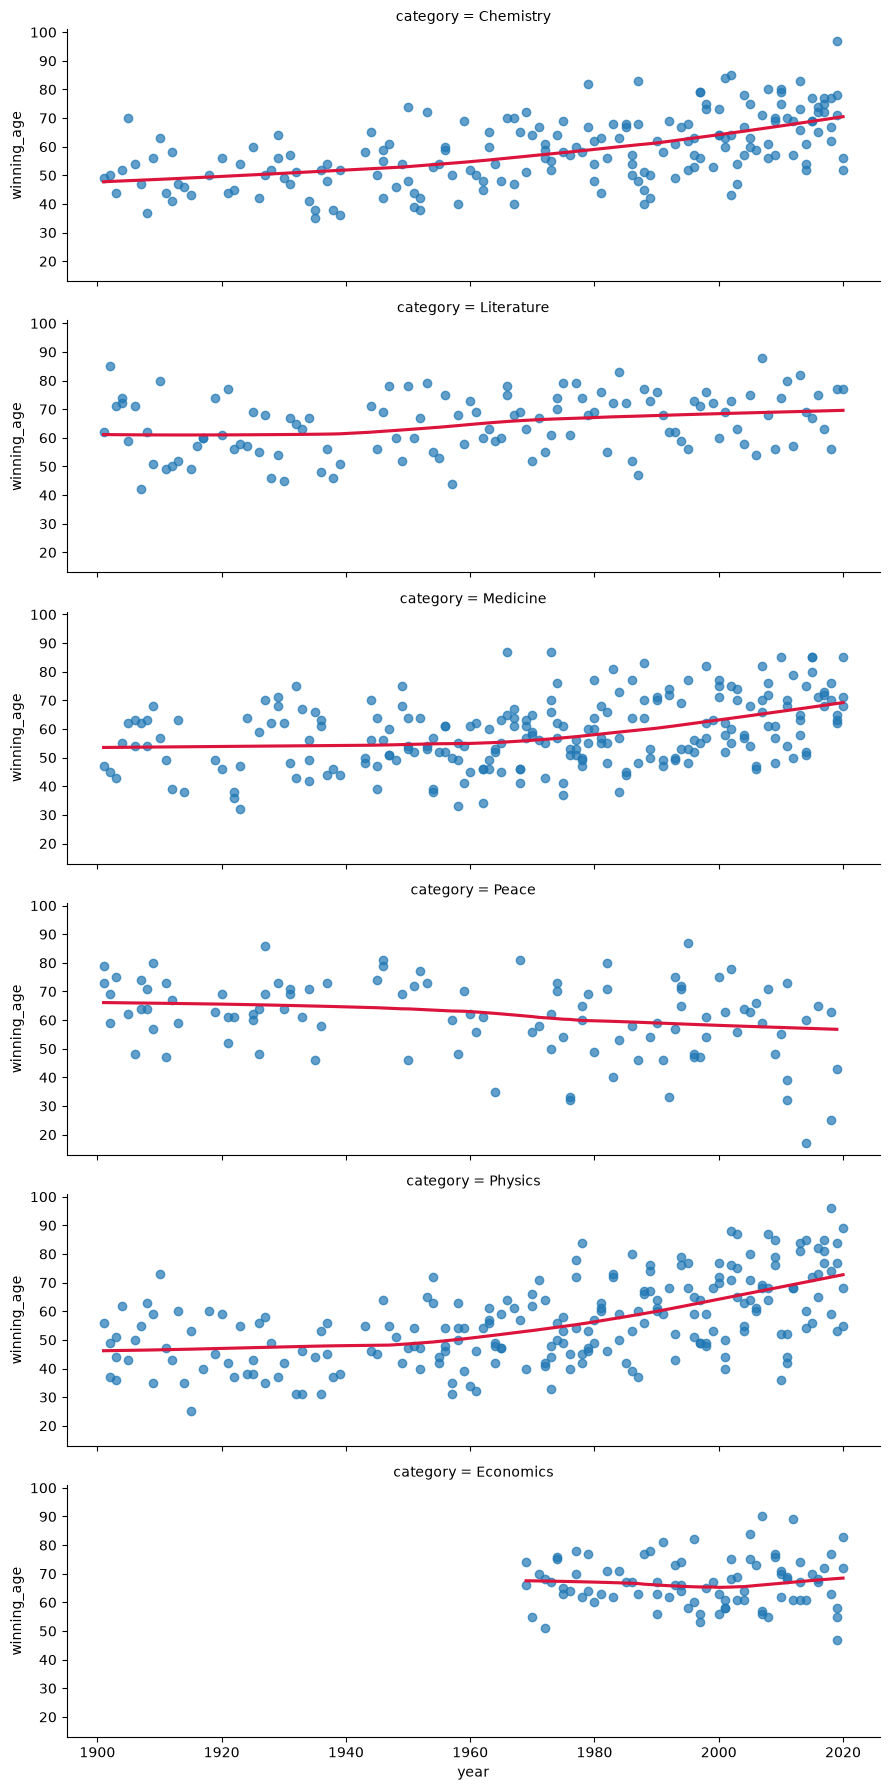

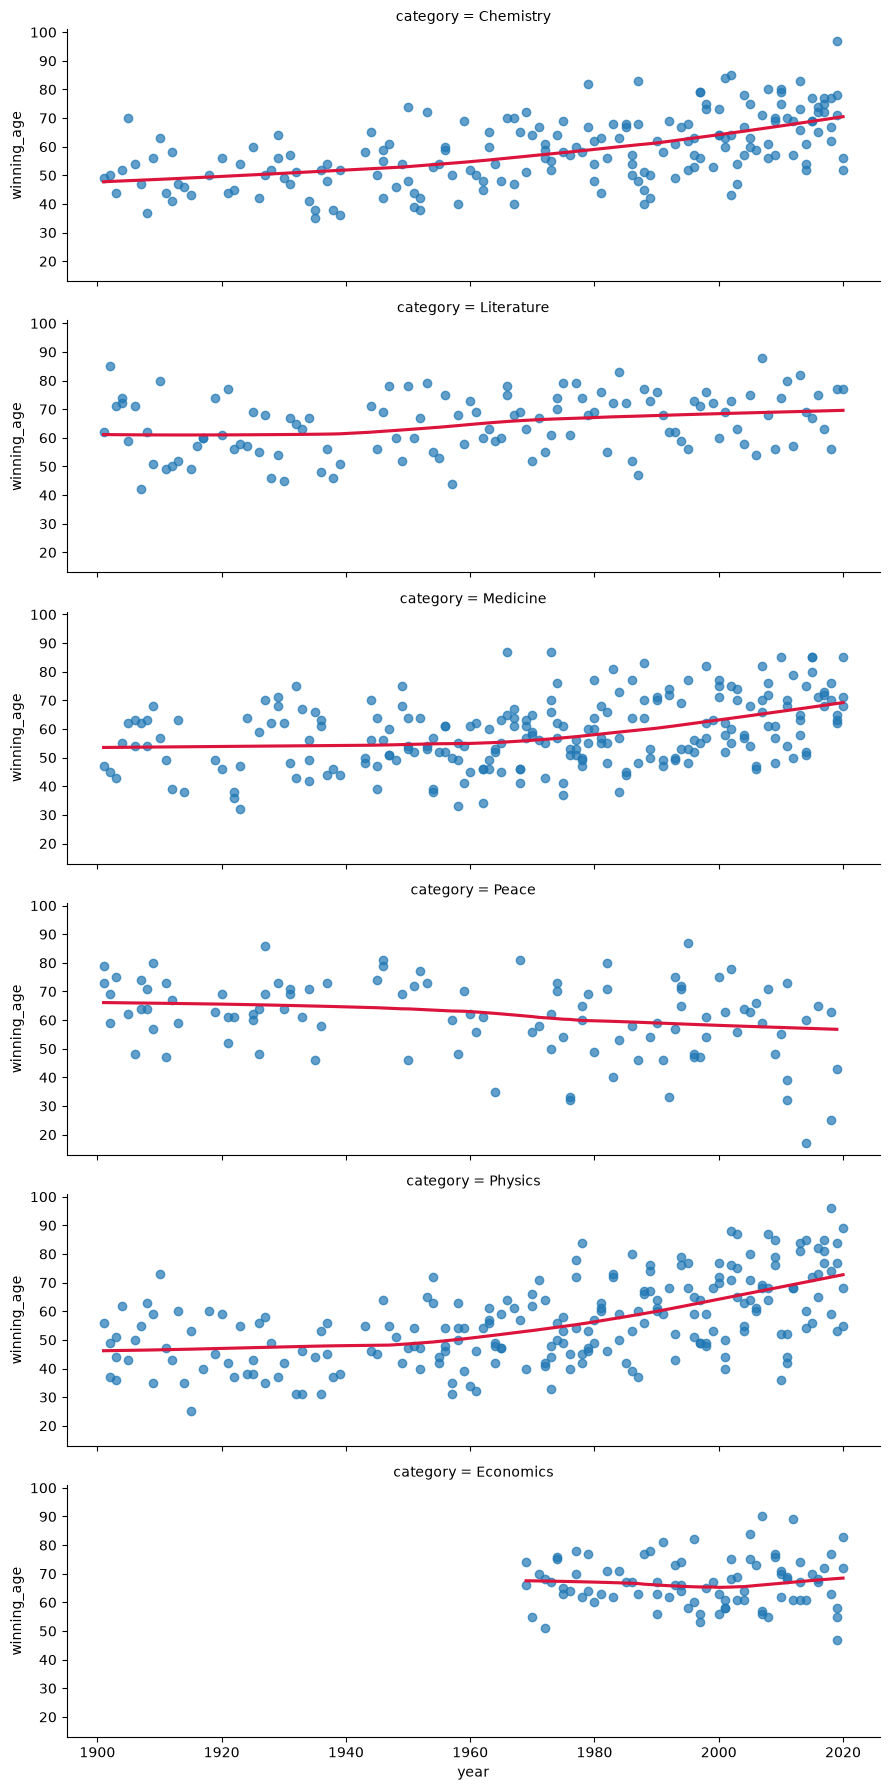

In [21]:
charts.winning_age_by_category_facets(df_age)

## Step 8: Learning points and summary (lecture 590)

Reviewed: finding NaN values, converting objects and strings to numbers, donut and bar charts with plotly, a rolling average for time series, `.value_counts()`, `.groupby()`, `.merge()`, `.sort_values()` and `.agg()`.

New: a choropleth map, bar charts of different segments of the data, sunburst charts, Seaborn `.lmplot()` with `row`, `hue` and `lowess`, how a different picture emerges when you look at the same data in different ways, and the distribution of the data in a Seaborn histogram.